In [ ]:
import re
from collections import Counter
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import FastText, KeyedVectors, Word2Vec
from IPython.display import display
from nltk.tokenize import sent_tokenize
from scipy.sparse import coo_matrix, csr_matrix
from scipy.stats import spearmanr
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

FileSystemPathPointer('C:\\Users\\valde\\AppData\\Roaming\\nltk_data\\tokenizers\\punkt_tab\\spanish')

---

### 1. Preparación de los corpus

In [74]:
data = Path('data')
ruta_noticias = data / 'df_total.csv'
ruta_quijote = data / 'don-quijote.txt'
ruta_suc = data / 'embeddings-m-model.vec'

noticias = pd.read_csv(ruta_noticias, encoding='utf-8-sig')
columnas = {str(c).lower().strip(): c for c in noticias.columns}
columna_texto = next((columnas[c] for c in
                      ['news', 'texto', 'text', 'noticia', 'contenido', 'content',
                       'body', 'article', 'titular', 'title'] if c in columnas), None)

documentos_noticias = noticias[columna_texto].dropna().astype(str).str.strip()
documentos_noticias = documentos_noticias[documentos_noticias != ''].tolist()

texto_original_quijote = ruta_quijote.read_text(encoding='utf-8-sig')
patron_inicio = re.compile(r'El\s+ingenioso\s+hidalgo\s+don\s+Quijote\s+de\s+la\s+Mancha', re.I)
patron_final = re.compile(
    r"End\s+of\s+Project\s+Gutenberg['’]s\s+Don\s+Quijote,\s+by\s+Miguel\s+de\s+Cervantes\s+Saavedra",
    re.I
)
coincidencia_inicio = patron_inicio.search(texto_original_quijote)
coincidencias_final = list(patron_final.finditer(texto_original_quijote, coincidencia_inicio.end()))
coincidencia_final = coincidencias_final[-1]

cuerpo_quijote = texto_original_quijote[coincidencia_inicio.end():coincidencia_final.start()].strip()
documentos_quijote = [cuerpo_quijote]

In [75]:
patron_urls = re.compile(r'(?:https?://|www\.)\S+', flags=re.IGNORECASE)
patron_tokens = re.compile(r'[^\W_]+', flags=re.UNICODE)

def tokenizar(texto):
    texto = patron_urls.sub(' ', texto.lower())
    return patron_tokens.findall(texto)

def preparar_corpus(documentos):
    oraciones = []
    for documento in documentos:
        partes = sent_tokenize(documento, language='spanish')
        for parte in partes:
            tokens = tokenizar(parte)
            if tokens:
                oraciones.append(tokens)
    return oraciones

oraciones_noticias = preparar_corpus(documentos_noticias)

oraciones_quijote = preparar_corpus(documentos_quijote)

**¿Qué normalización se utilizó?**

Se convirtieron las palabras a minúsculas y se eliminaron URLs y puntuación, pero se conservaron los números y las tildes. Esto permite reducir variantes innecesarias sin perder información que puede ser importante en noticias, como cifras o diferencias entre palabras. Además, en el vocabulario SUC cargado de 200,000 términos aparecen “españa”, “espana”, “año” y “ano”, pero no “España”, por lo que usar minúsculas y mantener tildes resulta compatible con esta comparación.

**¿Vale la pena quitar stopwords o lematizar antes de entrenar embeddings?**

Para este laboratorio no conviene. Aunque en el Lab 1 se eliminaron stopwords y se lematizó para reducir el vocabulario, aquí las palabras vecinas son las que permiten aprender el contexto. Si quitamos palabras como “de” o “la”, las ventanas juntarían palabras que originalmente no estaban cerca. Además, la lematización podría hacer que formas distintas, como “gobiernos” y “gobernó”, pierdan parte de su información gramatical.

In [76]:
frecuencias_noticias = Counter(t for oracion in oraciones_noticias for t in oracion)
frecuencias_quijote = Counter(t for oracion in oraciones_quijote for t in oracion)

total_tokens_noticias = sum(frecuencias_noticias.values())
total_tokens_quijote = sum(frecuencias_quijote.values())

tabla_corpus = pd.DataFrame([
    ['Noticias', len(documentos_noticias), len(oraciones_noticias),
     total_tokens_noticias, len(frecuencias_noticias)],
    ['Don Quijote', len(documentos_quijote), len(oraciones_quijote),
     total_tokens_quijote, len(frecuencias_quijote)]
], columns=['Corpus', 'Documentos', 'Oraciones', 'Tokens', 'Tipos'])

display(tabla_corpus)

,Corpus,Documentos,Oraciones,Tokens,Tipos
0,Noticias,1213,15423,637537,29518
1,Don Quijote,1,9512,381218,22942


In [77]:
def vocabulario_min_count(nombre, frecuencias):
    filas = []
    total = sum(frecuencias.values())
    for min_count in [1, 2, 5]:
        vocabulario = {palabra for palabra, f in frecuencias.items() if f >= min_count}
        tokens_fuera = sum(f for f in frecuencias.values() if f < min_count)
        porcentaje = 100 * tokens_fuera / total if total else 0
        filas.append([nombre, min_count, len(vocabulario), tokens_fuera, round(porcentaje, 2)])
    return filas


resultados_vocabulario = (
    vocabulario_min_count('Noticias', frecuencias_noticias)
    + vocabulario_min_count('Don Quijote', frecuencias_quijote)
)
tabla_vocabulario = pd.DataFrame(
    resultados_vocabulario,
    columns=['Corpus', 'min_count', 'Tamaño vocabulario', 'Tokens fuera', '% tokens fuera']
)
display(tabla_vocabulario)

,Corpus,min_count,Tamaño vocabulario,Tokens fuera,% tokens fuera
0,Noticias,1,29518,0,0.00
1,Noticias,2,17135,12383,1.94
2,Noticias,5,8888,34346,5.39
3,Don Quijote,1,22942,0,0.00
4,Don Quijote,2,11760,11182,2.93
5,Don Quijote,5,5301,28120,7.38


In [78]:
limite_suc = 200_000

if 'suc' not in globals():
    suc = KeyedVectors.load_word2vec_format(str(ruta_suc), limit=limite_suc)

print(f'Vectores SUC cargados: {len(suc.key_to_index):,}')
print(f'Dimensiones: {suc.vector_size}')

palabras = ['españa', 'España', 'espana', 'año', 'ano']
tabla_suc = pd.DataFrame([
    [palabra, palabra in suc.key_to_index] for palabra in palabras
], columns=['Palabra', '¿Existe en SUC cargado?'])
display(tabla_suc)


Vectores SUC cargados: 200,000
Dimensiones: 100


,Palabra,¿Existe en SUC cargado?
0,españa,True
1,España,False
2,espana,True
3,año,True
4,ano,True


In [79]:
def pares_skipgram(tokens, ventana=2):
    pares = []
    for i, palabra in enumerate(tokens):
        inicio = max(0, i - ventana)
        fin = min(len(tokens), i + ventana + 1)
        for j in range(inicio, fin):
            if i != j:
                pares.append((palabra, tokens[j]))
    return pares

oracion_ejemplo = next((s for s in oraciones_noticias if 6 <= len(s) <= 12), None)

pares_ejemplo = pares_skipgram(oracion_ejemplo, ventana=2)
print('Oración:', ' '.join(oracion_ejemplo))
print(f'Tokens: {len(oracion_ejemplo)} | Pares: {len(pares_ejemplo)}')
display(pd.DataFrame(pares_ejemplo, columns=['Palabra central', 'Contexto']))

Oración: como último punto se debe garantizar que los avances lleguen a todos
Tokens: 12 | Pares: 42


,Palabra central,Contexto
0,como,último
1,como,punto
2,último,como
3,último,punto
4,último,se
5,punto,como
6,punto,último
7,punto,se
8,punto,debe
9,se,último


In [80]:
def contar_pares(oraciones, ventana):
    total = 0
    for oracion in oraciones:
        n = len(oracion)
        for distancia in range(1, min(ventana, n - 1) + 1):
            total += 2 * (n - distancia)
    return total

assert contar_pares([oracion_ejemplo], 2) == len(pares_ejemplo)

resultados_pares = []
for ventana in [2, 5]:
    total_pares = contar_pares(oraciones_noticias, ventana)
    razon = total_pares / total_tokens_noticias if total_tokens_noticias else 0
    resultados_pares.append([ventana, total_tokens_noticias, total_pares, round(razon, 2)])

tabla_pares = pd.DataFrame(
    resultados_pares,
    columns=['Ventana', 'Tokens del corpus', 'Pares skip-gram', 'Pares por token']
)
display(tabla_pares)

,Ventana,Tokens del corpus,Pares skip-gram,Pares por token
0,2,637537,2457706,3.86
1,5,637537,5914404,9.28


**¿Por qué Word2Vec no necesita datos etiquetados?**

Porque aprende de las propias palabras del texto: toma una palabra central y utiliza las palabras cercanas como ejemplos de contexto. Con las 637,537 palabras del corpus de noticias se generaron 2,457,706 pares con ventana 2 y 5,914,404 con ventana 5, es decir, unos 3.86 y 9.28 pares por token. Los pares crecen con la ventana y son muchos más que los tokens, y se obtienen automáticamente, sin que alguien tenga que asignar una categoría o etiqueta a cada noticia.

---

### 2. Co-ocurrencia, PPMI y SVD

In [81]:
vocabulario_2000 = [palabra for palabra, _ in frecuencias_noticias.most_common(2000)]
indice_palabras = {palabra: i for i, palabra in enumerate(vocabulario_2000)}

def construir_coocurrencias(oraciones, indices, ventana=2):
    n = len(indices)
    matriz = csr_matrix((n, n), dtype=np.int32)
    filas, columnas = [], []

    for oracion in oraciones:
        ids = [indices.get(palabra, -1) for palabra in oracion]
        for distancia in range(1, ventana + 1):
            for i in range(len(ids) - distancia):
                a, b = ids[i], ids[i + distancia]
                if a == -1 or b == -1:
                    continue
                filas.extend([a, b])
                columnas.extend([b, a])

                if len(filas) >= 200_000:
                    bloque = coo_matrix(
                        (np.ones(len(filas), dtype=np.int32), (filas, columnas)),
                        shape=(n, n)
                    ).tocsr()
                    matriz += bloque
                    filas.clear()
                    columnas.clear()

    if filas:
        matriz += coo_matrix(
            (np.ones(len(filas), dtype=np.int32), (filas, columnas)),
            shape=(n, n)
        ).tocsr()

    return matriz


matriz_cooc = construir_coocurrencias(oraciones_noticias, indice_palabras, ventana=2)
porcentaje_ceros_cooc = 100 * (1 - matriz_cooc.nnz / (matriz_cooc.shape[0] * matriz_cooc.shape[1]))

print('Forma de la matriz:', matriz_cooc.shape)
print(f'Ceros: {porcentaje_ceros_cooc:.2f}%')
print(f'Entradas distintas de cero: {matriz_cooc.nnz:,}')

Forma de la matriz: (2000, 2000)
Ceros: 93.51%
Entradas distintas de cero: 259,489


In [82]:
vectorizador = CountVectorizer(
    vocabulary=indice_palabras,
    tokenizer=tokenizar,
    token_pattern=None,
    lowercase=False
)
matriz_bow = vectorizador.transform(documentos_noticias)

comparacion = pd.DataFrame([
    ['Co-ocurrencia', str(matriz_cooc.shape), porcentaje_ceros_cooc],
    ['BoW (noticias)', str(matriz_bow.shape),
     100 * (1 - matriz_bow.nnz / (matriz_bow.shape[0] * matriz_bow.shape[1]))]
], columns=['Matriz', 'Forma', '% de ceros'])
display(comparacion.round(2))

,Matriz,Forma,% de ceros
0,Co-ocurrencia,"(2000, 2000)",93.51
1,BoW (noticias),"(1213, 2000)",91.88


**¿Cómo se compara la dispersión con la matriz BoW del Laboratorio 2?**

La matriz de co-ocurrencia de este laboratorio tiene 93.51% de ceros, mientras que la BoW calculada aquí, usando las mismas 2,000 palabras, tiene 91.88%. En cambio, la BoW original del Lab 2 tuvo 99.17% de ceros, con 1,137 documentos y 23,412 términos. No es una comparación directa, porque en el Lab 2 se quitaron stopwords, se lematizó y se utilizó un vocabulario mucho mayor. Al incluir palabras menos frecuentes normalmente aumenta la dispersión.

In [83]:
pares_palabras = [
    ('empresa', 'telecomunicaciones', 'Relacionadas'),
    ('gobierno', 'nacional', 'Relacionadas'),
    ('gobierno', 'federal', 'Relacionadas'),
    ('empresa', 'sánchez', 'No relacionadas'),
    ('gobierno', 'telecomunicaciones', 'No relacionadas')
]

filas_similitud = []
for palabra1, palabra2, relacion in pares_palabras:
    a, b = indice_palabras[palabra1], indice_palabras[palabra2]
    similitud = cosine_similarity(matriz_cooc[a], matriz_cooc[b])[0, 0]
    filas_similitud.append([palabra1, palabra2, relacion, similitud])

tabla_similitud = pd.DataFrame(
    filas_similitud, columns=['Palabra 1', 'Palabra 2', 'Relación', 'Coseno']
)
display(tabla_similitud.round(4))

promedio_rel = tabla_similitud.loc[tabla_similitud['Relación'] == 'Relacionadas', 'Coseno'].mean()
promedio_no_rel = tabla_similitud.loc[tabla_similitud['Relación'] == 'No relacionadas', 'Coseno'].mean()

print(f'Promedio relacionadas: {promedio_rel:.4f}')
print(f'Promedio no relacionadas: {promedio_no_rel:.4f}')


,Palabra 1,Palabra 2,Relación,Coseno
0,empresa,telecomunicaciones,Relacionadas,0.6100
1,gobierno,nacional,Relacionadas,0.7396
2,gobierno,federal,Relacionadas,0.2999
3,empresa,sánchez,No relacionadas,0.4909
4,gobierno,telecomunicaciones,No relacionadas,0.4373


Promedio relacionadas: 0.5498
Promedio no relacionadas: 0.4641


**¿La similitud coseno coincide con la intuición?**

Solo en parte. Los pares relacionados tienen un coseno promedio de 0.55 y los no relacionados de 0.46, así que la diferencia existe pero es pequeña. "gobierno" con "nacional" (0.74) y "empresa" con "telecomunicaciones" (0.61) salen altos, pero "gobierno" con "federal" tiene solo 0.30, menos que el par no relacionado "empresa" con "sánchez" (0.49). Esto pasa porque el corpus es pequeño, trata temas económicos y políticos, y las filas de conteos están dominadas por palabras muy comunes como "de" o "la", que hacen parecer similares a casi cualquier par de palabras.

In [84]:
def top_contextos(matriz, palabra, nombre_columna, n=10):
    if palabra not in indice_palabras:
        print(f'{palabra!r} no aparece en el vocabulario de 2,000 palabras.')
        return pd.DataFrame(columns=['Palabra', 'Contexto', nombre_columna])

    idx = indice_palabras[palabra]
    valores = matriz[idx].toarray().ravel() if hasattr(matriz, 'toarray') else matriz[idx]
    orden = np.argsort(valores)[::-1]
    mejores = [i for i in orden if valores[i] > 0 and i != idx][:n]

    return pd.DataFrame({
        'Palabra': palabra,
        'Contexto': [vocabulario_2000[i] for i in mejores],
        nombre_columna: [valores[i] for i in mejores]
    })


tabla_cooc = pd.concat([
    top_contextos(matriz_cooc, palabra, 'Co-ocurrencias')
    for palabra in ['empresa', 'gobierno']
], ignore_index=True)
display(tabla_cooc)

,Palabra,Contexto,Co-ocurrencias
0,empresa,la,205
1,empresa,de,152
2,empresa,una,65
3,empresa,en,48
4,empresa,que,47
5,empresa,y,39
6,empresa,a,33
7,empresa,con,28
8,empresa,para,19
9,empresa,como,17


**¿Qué tipo de palabras dominan la lista**

Dominan palabras muy comunes, como artículos, preposiciones y conectores: para “empresa” aparecen “la” (205), “de” (152) y “una” (65), mientras que para “gobierno” destacan “el” (220), “del” (108) y “de” (84). Esto ocurre porque estas palabras aparecen cerca de muchísimos términos, aunque por sí solas no describen claramente su significado.

In [85]:
conteos = matriz_cooc.toarray().astype(np.float64)
total_cooc = conteos.sum()
if total_cooc == 0:
    raise ValueError('La matriz de co-ocurrencia no contiene pares.')

p_wc = conteos / total_cooc
p_w = p_wc.sum(axis=1, keepdims=True)
p_c = p_wc.sum(axis=0, keepdims=True)

razon = np.divide(
    p_wc, p_w * p_c,
    out=np.zeros_like(p_wc), where=(p_w * p_c) > 0
)
with np.errstate(divide='ignore'):
    matriz_ppmi = np.maximum(0, np.log2(razon))
matriz_ppmi[~np.isfinite(matriz_ppmi)] = 0

print('Forma de PPMI:', matriz_ppmi.shape)
print(f'Ceros en PPMI: {100 * np.mean(matriz_ppmi == 0):.2f}%')

Forma de PPMI: (2000, 2000)
Ceros en PPMI: 94.79%


In [86]:
tabla_ppmi = pd.concat([
    top_contextos(matriz_ppmi, palabra, 'PPMI')
    for palabra in ['empresa', 'gobierno']
], ignore_index=True)
display(tabla_ppmi.round(3))

,Palabra,Contexto,PPMI
0,empresa,telecomunicaciones,5.431
1,empresa,líder,5.155
2,empresa,llega,5.110
3,empresa,especializada,5.006
4,empresa,cualquier,4.840
5,empresa,estadounidense,4.663
6,empresa,asegurar,4.568
7,empresa,colombiana,4.535
8,empresa,criterios,4.472
9,empresa,española,4.256


**¿Qué cambió al utilizar PPMI y por qué?**

Con los conteos simples predominaban palabras como “la”, “de” y “el”, pero con PPMI aparecen asociaciones más específicas. Por ejemplo, para “empresa” destacan “telecomunicaciones” (5.431) y “líder” (5.155), y para “gobierno” aparecen “corporativo” (7.232) y “federal” (5.805). Esto pasa porque PPMI valora las co-ocurrencias que son más frecuentes de lo esperado para esas palabras, en vez de premiar solo a las palabras que más se repiten. También puede resaltar asociaciones poco frecuentes que no siempre son las más intuitivas.

In [87]:
svd = TruncatedSVD(n_components=100, random_state=42)
vectores_svd = svd.fit_transform(matriz_ppmi)

kv_svd = KeyedVectors(vector_size=100)
kv_svd.add_vectors(vocabulario_2000, vectores_svd.astype(np.float32))

ruta_svd = data / 'noticias_ppmi_svd_100.kv'
ruta_svd.parent.mkdir(parents=True, exist_ok=True)
kv_svd.save(str(ruta_svd))

print('Dimensiones de los vectores:', vectores_svd.shape)
print(f'Varianza explicada acumulada: {svd.explained_variance_ratio_.sum():.2%}')
print('Modelo guardado en:', ruta_svd)
print('Ejemplo de vector para empresa:', kv_svd['empresa'][:5]
      if 'empresa' in kv_svd else 'No disponible')

Dimensiones de los vectores: (2000, 100)
Varianza explicada acumulada: 24.94%
Modelo guardado en: data\noticias_ppmi_svd_100.kv
Ejemplo de vector para empresa: [ 8.797043  -2.7684753 -4.249758   0.523882  -3.094177 ]


**¿Por qué las filas de la matriz son vectores de palabras y qué resuelven PPMI y SVD?**

Cada fila es un vector porque muestra cuántas veces aparece una palabra cerca de las demás, dos palabras con contextos parecidos tendrán filas similares. PPMI reduce el peso de palabras muy comunes y resalta asociaciones más informativas. SVD resume esos patrones en 100 dimensiones, por lo que los vectores ocupan menos espacio y pueden captar relaciones que no dependen de compartir exactamente los mismos contextos. En este corpus se obtuvieron 2,000 vectores de 100 dimensiones, con una varianza explicada acumulada de 24.94%.

---

### 4. Entrenar Word2Vec y fastText

In [88]:
config_base = dict(vector_size=100, window=5, min_count=2, sg=1, negative=5, epochs=10, workers=1, seed=42)
configuraciones = {
    'Base (skip-gram)': {},
    'CBOW': {'sg': 0},
    'Ventana 2': {'window': 2},
    'Ventana 10': {'window': 10},
    '50 dimensiones': {'vector_size': 50},
    '300 dimensiones': {'vector_size': 300},
}
modelos_noticias = {}
tiempos = {}
for nombre, cambios in configuraciones.items():
    config = {**config_base, **cambios}
    inicio = perf_counter()
    modelos_noticias[nombre] = Word2Vec(sentences=oraciones_noticias, **config)
    tiempos[nombre] = perf_counter() - inicio
    print(f'{nombre}: {tiempos[nombre]:.2f} segundos')

Base (skip-gram): 25.47 segundos
CBOW: 8.32 segundos
Ventana 2: 14.80 segundos
Ventana 10: 40.61 segundos
50 dimensiones: 24.64 segundos
300 dimensiones: 40.02 segundos


In [89]:
preferidas = ['banco', 'gobierno', 'empresa', 'mercado', 'tecnología', 'sostenibilidad']
vocab_comun = set.intersection(*(set(m.wv.key_to_index) for m in modelos_noticias.values()))
controles = [p for p in preferidas if p in vocab_comun]
controles += [p for p, _ in frecuencias_noticias.most_common() if p in vocab_comun and p not in controles][:6-len(controles)]
assert len(controles) == 6, 'No hay seis palabras disponibles para comparar.'
print('Palabras de control:', controles)

filas_modelos = []
for nombre, modelo in modelos_noticias.items():
    fila = {'Modelo': nombre, 'sg': modelo.sg, 'window': modelo.window,
            'vector_size': modelo.vector_size, 'min_count': modelo.min_count,
            'negative': modelo.negative, 'epochs': modelo.epochs,
            'Tiempo (s)': round(tiempos[nombre], 2)}
    for palabra in controles:
        fila[palabra] = ', '.join(p for p, _ in modelo.wv.most_similar(palabra, topn=5))
    filas_modelos.append(fila)
tabla_modelos = pd.DataFrame(filas_modelos)
display(tabla_modelos)

Palabras de control: ['banco', 'gobierno', 'empresa', 'mercado', 'tecnología', 'sostenibilidad']


,Modelo,sg,window,vector_size,min_count,negative,epochs,Tiempo (s),banco,gobierno,empresa,mercado,tecnología,sostenibilidad
0,Base (skip-gram),1,5,100,2,5,10,25.47,"central, agrario, república, popular, sudameris","congreso, consejo, intervenir, mandatario, gre...","startup, emergente, innovadora, paack, plataforma","sector, colombiano, consolidándose, accionario...","estandarización, computación, definitiva, apal...","digitalización, diversidad, sociedad, biodiver..."
1,CBOW,0,5,100,2,5,10,8.32,"cordillera, supervisor, grupo, área, ranking","congreso, estado, apecic, periódico, gremio","plataforma, compañía, marca, startup, iniciativa","país, sector, mundo, turismo, territorio","digitalización, tecnológica, transformación, s...","innovación, digitalización, transformación, em..."
2,Ventana 2,1,2,100,2,5,10,14.80,"central, gnb, bce, dominicana, sudameris","congreso, bce, consejo, regulador, comité","plataforma, startup, película, matriz, veridas","sector, régimen, fútbol, conglomerado, empleo","publicidad, internet, educativa, funcionalidad...","digitalización, liderazgo, diversidad, equidad..."
3,Ventana 10,1,10,100,2,5,10,40.61,"central, agrario, república, popular, finandina","congreso, expresidente, intervenir, reforma, p...","compañía, emergente, startup, biotecnología, p...","sector, accionario, colombiano, desconocido, r...","devops, ntf, ayudarle, neurálgico, estandariza...","monográficos, prioridades, suscríbete, socieda..."
4,50 dimensiones,1,5,50,2,5,10,24.64,"central, entidad, popular, república, agrario","congreso, intervenir, gremial, anuncio, consejo","startup, compañía, innovadora, plataforma, liga","apetito, colombiano, solvencia, ganando, admin...","nube, estandarización, autentificación, portal...","diversidad, biodiversidad, salvar, sociedad, d..."
5,300 dimensiones,1,5,300,2,5,10,40.02,"central, popular, agrario, república, sudameris","congreso, intervenir, gremial, plan, mandatario","startup, emergente, compañía, biotecnología, a...","colombiano, sector, mercados, regulador, conso...","ntf, innovadora, estandarización, apalancarse,...","digitalización, alineado, diversidad, ballabri..."


**¿Las ventanas pequeñas dan vecinos más sintácticos (otras formas de la misma palabra) y las grandes, más temáticos?**

No se observa una diferencia completamente clara. Con ventana 2, "banco" se relaciona con "central", "gnb" y "bce", mientras que con ventana 10 aparecen "central", "agrario" y "república". Para "empresa", la ventana 2 devuelve "plataforma" y "startup", y la ventana 10 devuelve "compañía", "emergente" y "biotecnología". Para "mercado", la ventana 2 incluye "régimen" y "fútbol", y la ventana 10 incluye "accionario" y "colombiano". La ventana grande parece dar asociaciones más temáticas, pero la pequeña tampoco se limita a formas gramaticales de la misma palabra. Además, la ventana 10 tardó más que la ventana 2 (ver la columna de tiempo).

In [90]:
inicio = perf_counter()
modelo_quijote = Word2Vec(sentences=oraciones_quijote, **config_base)
tiempo_quijote = perf_counter() - inicio
print(f'Tiempo de entrenamiento del Quijote: {tiempo_quijote:.2f} segundos')

vocab_ambos = set(modelos_noticias['Base (skip-gram)'].wv.key_to_index) & set(modelo_quijote.wv.key_to_index)
candidatas_ambos = ['señor', 'dinero', 'casa', 'palabra', 'hombre', 'tiempo', 'amigo', 'mundo']
palabras_ambos = [p for p in candidatas_ambos if p in vocab_ambos][:5]
assert len(palabras_ambos) == 5, 'Faltan palabras en común; ajuste la lista.'

comparacion_corpus = pd.DataFrame([{
    'Palabra': p,
    'Noticias': ', '.join(w for w, _ in modelos_noticias['Base (skip-gram)'].wv.most_similar(p, topn=5)),
    'Quijote': ', '.join(w for w, _ in modelo_quijote.wv.most_similar(p, topn=5))
} for p in palabras_ambos])
display(comparacion_corpus)

Tiempo de entrenamiento del Quijote: 14.70 segundos


,Palabra,Noticias,Quijote
0,señor,"tendero, arenera, fieles, unimos, comimo","castellano, álvaro, pedro, perdóneme, recio"
1,dinero,"crediticio, permitía, vivir, virtuoso, recibir","dueño, capellán, haréis, tema, pareciéndome"
2,casa,"pasiva, teletrabajar, reformar, ficha, silla","aldea, compañía, hija, corte, presente"
3,palabra,"utópico, pendiente, empírica, técnicamente, im...","hablar, respondelle, desató, respondiese, resp..."
4,hombre,"entretanto, rehabilitar, hm, residente, irrump...","talle, honrado, viejo, entero, mancebo"


**¿Qué significa que el "significado viene del corpus"?**

Significa que el modelo aprende las relaciones entre palabras según los contextos en los que aparecen. Por ejemplo, en noticias “dinero” se acerca a “crediticio”, mientras que en el Quijote aparece cerca de “dueño” y “capellán”. También “casa” se relaciona con “teletrabajar” en noticias y con “aldea” y “hacienda” en el Quijote. Esto muestra que una misma palabra puede tener vecinos distintos dependiendo del tipo de texto, aunque algunos resultados también pueden deberse al tamaño del corpus y al entrenamiento.

In [91]:
inicio = perf_counter()
modelo_fasttext = FastText(sentences=oraciones_noticias, **config_base)
print(f'FastText: {perf_counter() - inicio:.2f} segundos')

candidatos_oov = {
    'Error de dedo': ['govierno', 'empreza', 'bannco'],
    'Conjugación poco común': ['gobernásemos', 'financiásemos', 'comercializásemos'],
    'Palabra inventada': ['criptoempresa', 'tecnobanco', 'mercadocripto']
}
ejemplos_oov = {}
for categoria, candidatos in candidatos_oov.items():
    palabra = next((p for p in candidatos if p not in modelo_fasttext.wv.key_to_index
                    and p not in modelos_noticias['Base (skip-gram)'].wv.key_to_index), None)
    if palabra is None:
        raise ValueError(f'No se encontró una palabra OOV para {categoria}; ajuste los candidatos.')
    ejemplos_oov[categoria] = palabra

filas_oov = []
for categoria, palabra in ejemplos_oov.items():
    vecinos = modelo_fasttext.wv.most_similar(palabra, topn=5)
    try:
        vector_w2v = modelos_noticias['Base (skip-gram)'].wv[palabra]
        resultado_w2v = f'Vector disponible: {len(vector_w2v)} dimensiones'
    except KeyError:
        resultado_w2v = 'KeyError: fuera del vocabulario'
    filas_oov.append({'Tipo': categoria, 'Palabra': palabra,
                      'Dimensiones FastText': len(modelo_fasttext.wv[palabra]),
                      'Vecinos FastText': ', '.join(w for w, _ in vecinos),
                      'Word2Vec': resultado_w2v})
display(pd.DataFrame(filas_oov))

FastText: 60.46 segundos


,Tipo,Palabra,Dimensiones FastText,Vecinos FastText,Word2Vec
0,Error de dedo,govierno,100,"invierno, infierno, gobierno, poliestireno, be...",KeyError: fuera del vocabulario
1,Conjugación poco común,gobernásemos,100,"imaginemos, sabemos, decidimos, pasemos, andemos",KeyError: fuera del vocabulario
2,Palabra inventada,criptoempresa,100,"empresa, criptografía, cripto, criptomoneda, i...",KeyError: fuera del vocabulario


**¿Por qué FastText puede representar palabras que Word2Vec no conoce?**

FastText utiliza fragmentos de caracteres (subpalabras) para construir vectores, por lo que puede representar palabras que no aparecieron durante el entrenamiento. En los resultados, "govierno" queda cerca de "gobierno", aunque también aparecen "invierno" e "infierno" porque comparten fragmentos de letras; "gobernásemos" obtiene como vecinos otras formas verbales con terminaciones parecidas, como "sabemos" y "andemos"; y "criptoempresa" se relaciona con "empresa", "cripto" y "criptomoneda". Las tres palabras tienen vectores de 100 dimensiones en FastText, mientras que Word2Vec devuelve un KeyError porque no están en su vocabulario. Esto no significa que FastText siempre interprete correctamente las palabras inventadas.

In [92]:
nombre_elegido = 'Base (skip-gram)'
modelo_elegido = modelos_noticias[nombre_elegido]

print(f'Modelo elegido: {nombre_elegido}')

Modelo elegido: Base (skip-gram)


**¿Cuál es el mejor modelo propio y por qué?**

Elegí el modelo base (skip-gram, ventana 5, 100 dimensiones). Sus vecinos son los más coherentes con el tema de las noticias: "banco" se acerca a otros bancos ("central", "agrario", "república", "popular", "sudameris"), "empresa" a "startup", "emergente" e "innovadora", y "sostenibilidad" a "digitalización", "diversidad" y "biodiversidad". CBOW dio vecinos menos coherentes, como "cordillera", "supervisor" y "ranking" para "banco". Las variantes con ventana 10 o con 300 dimensiones dieron vecinos parecidos a los del modelo base pero tardaron más, y la de ventana 2 mezcló palabras como "película" y "veridas" para "empresa". Además, skip-gram suele funcionar mejor con palabras poco frecuentes, lo que ayuda en un corpus pequeño.

---

### 5. Similitud, vecinos y analogías

In [93]:
modelos_5 = {
    'SVD + PPMI': kv_svd,
    'Word2Vec noticias': modelo_elegido.wv,
    'Word2Vec Quijote': modelo_quijote.wv,
    'fastText SUC': suc,
}

print('Modelos:', ', '.join(modelos_5.keys()))

Modelos: SVD + PPMI, Word2Vec noticias, Word2Vec Quijote, fastText SUC


#### 5.1 Similitud coseno y vecinos

In [94]:
def coseno(u, v):
    u = np.asarray(u, dtype=np.float64)
    v = np.asarray(v, dtype=np.float64)
    norma_u = np.linalg.norm(u)
    norma_v = np.linalg.norm(v)
    if norma_u == 0 or norma_v == 0:
        return np.nan
    return float(np.dot(u, v) / (norma_u * norma_v))

pares_verificacion = [
    ('banco', 'gobierno'),
    ('empresa', 'mercado'),
    ('tecnología', 'sostenibilidad'),
]

filas = []
for nombre, kv in modelos_5.items():
    for a, b in pares_verificacion:
        if a in kv.key_to_index and b in kv.key_to_index:
            propio = coseno(kv[a], kv[b])
            gensim = float(kv.similarity(a, b))
            filas.append({
                'Modelo': nombre,
                'Par': f'{a} / {b}',
                'Coseno NumPy': propio,
                'similarity gensim': gensim,
                'Diferencia': abs(propio - gensim),
            })

tabla_coseno = pd.DataFrame(filas)
display(tabla_coseno.round(6))

,Modelo,Par,Coseno NumPy,similarity gensim,Diferencia
0,SVD + PPMI,banco / gobierno,0.561676,0.561676,0.0
1,SVD + PPMI,empresa / mercado,0.270839,0.270839,0.0
2,SVD + PPMI,tecnología / sostenibilidad,0.468240,0.468240,0.0
3,Word2Vec noticias,banco / gobierno,0.285587,0.285587,0.0
4,Word2Vec noticias,empresa / mercado,0.255498,0.255498,0.0
5,Word2Vec noticias,tecnología / sostenibilidad,0.399312,0.399312,0.0
6,Word2Vec Quijote,banco / gobierno,0.409615,0.409615,0.0
7,fastText SUC,banco / gobierno,0.561804,0.561804,0.0
8,fastText SUC,empresa / mercado,0.574913,0.574913,0.0
9,fastText SUC,tecnología / sostenibilidad,0.505609,0.505609,0.0


In [95]:
candidatas_5 = ['empresa', 'gobierno', 'banco', 'dinero', 'casa', 'ciudad', 'país', 'tiempo', 'hombre', 'mundo']
comunes_5 = set.intersection(*(set(kv.key_to_index) for kv in modelos_5.values()))
palabras_5 = [p for p in candidatas_5 if p in comunes_5][:5]
assert len(palabras_5) == 5, 'Faltan palabras presentes en los cuatro modelos; ajuste la lista.'

filas_vecinos = []
for palabra in palabras_5:
    for nombre, kv in modelos_5.items():
        vecinos = kv.most_similar(palabra, topn=5)
        filas_vecinos.append({
            'Palabra': palabra,
            'Modelo': nombre,
            'Vecinos (top 5)': ', '.join(f'{w} ({s:.3f})' for w, s in vecinos)
        })

tabla_vecinos = pd.DataFrame(filas_vecinos)
display(tabla_vecinos)


,Palabra,Modelo,Vecinos (top 5)
0,empresa,SVD + PPMI,"plataforma (0.669), tecnología (0.668), compañ..."
1,empresa,Word2Vec noticias,"startup (0.643), emergente (0.618), innovadora..."
2,empresa,Word2Vec Quijote,"herida (0.866), novedad (0.856), demanda (0.85..."
3,empresa,fastText SUC,"compañía (0.824), constructora (0.794), subsid..."
4,gobierno,SVD + PPMI,"banco (0.562), comisión (0.547), cargo (0.537)..."
5,gobierno,Word2Vec noticias,"congreso (0.771), consejo (0.646), intervenir ..."
6,gobierno,Word2Vec Quijote,"condado (0.792), ínsula (0.788), pago (0.769),..."
7,gobierno,fastText SUC,"elgobierno (0.752), gobier (0.745), go­bierno ..."
8,banco,SVD + PPMI,"bbva (0.650), grupo (0.643), central (0.640), ..."
9,banco,Word2Vec noticias,"central (0.746), agrario (0.584), república (0..."


In [96]:
pares_antonimos = [
    ('bueno', 'malo'),
    ('subir', 'bajar'),
    ('ganar', 'perder'),
    ('público', 'privado'),
]

filas_antonimos = []
for par in pares_antonimos:
    for nombre, kv in modelos_5.items():
        a, b = par
        if a in kv.key_to_index and b in kv.key_to_index:
            filas_antonimos.append({
                'Par': f'{a} / {b}',
                'Modelo': nombre,
                'Coseno': kv.similarity(a, b)
            })
        else:
            filas_antonimos.append({
                'Par': f'{a} / {b}',
                'Modelo': nombre,
                'Coseno': np.nan
            })

tabla_antonimos = pd.DataFrame(filas_antonimos)
display(tabla_antonimos.pivot(index='Par', columns='Modelo', values='Coseno').round(4))


Modelo,SVD + PPMI,Word2Vec Quijote,Word2Vec noticias,fastText SUC
Par,,,,
bueno / malo,NaN,0.7928,0.7502,0.7174
ganar / perder,NaN,0.7115,0.6661,0.6895
público / privado,0.5406,NaN,0.7145,0.6533
subir / bajar,NaN,0.7958,0.8191,0.9372


**¿Por qué similitud distribucional no es lo mismo que sinonimia?**

Las similitudes de los antónimos son altas en los modelos que tienen estas palabras: en fastText SUC van de 0.65 a 0.94 y en el Quijote de 0.71 a 0.83. Esto pasa porque dos antónimos suelen aparecer en contextos muy parecidos. Por ejemplo, "ganar" y "perder" pueden aparecer en noticias sobre los mismos partidos, competencias o resultados. Por eso el coseno mide semejanza de contexto y no determina por sí mismo que dos palabras tengan el mismo significado.

#### 5.2 Conjunto de similitud propio

In [97]:
gold_20 = [
    ('empresa', 'compañía', 10),
    ('gobierno', 'estado', 8),
    ('mercado', 'economía', 8),
    ('banco', 'finanzas', 8),
    ('tecnología', 'innovación', 9),
    ('dinero', 'capital', 8),
    ('casa', 'hogar', 10),
    ('caballo', 'animal', 7),
    ('perro', 'gato', 6),
    ('fútbol', 'deporte', 8),
    ('médico', 'hospital', 7),
    ('universidad', 'estudiante', 6),
    ('presidente', 'gobierno', 7),
    ('empresa', 'hospital', 1),
    ('mercado', 'caballo', 0),
    ('gobierno', 'playa', 0),
    ('tecnología', 'árbol', 1),
    ('dinero', 'caballo', 1),
    ('casa', 'fútbol', 2),
    ('empresa', 'comida', 2),
]

gold_df = pd.DataFrame(gold_20, columns=['Palabra 1', 'Palabra 2', 'Puntaje humano'])
display(gold_df)

,Palabra 1,Palabra 2,Puntaje humano
0,empresa,compañía,10
1,gobierno,estado,8
2,mercado,economía,8
3,banco,finanzas,8
4,tecnología,innovación,9
5,dinero,capital,8
6,casa,hogar,10
7,caballo,animal,7
8,perro,gato,6
9,fútbol,deporte,8


In [98]:
resultados_spearman = []
for nombre, kv in modelos_5.items():
    humanos = []
    cosenos = []
    fuera = 0
    for a, b, score in gold_20:
        if a in kv.key_to_index and b in kv.key_to_index:
            humanos.append(score)
            cosenos.append(kv.similarity(a, b))
        else:
            fuera += 1
    rho, pvalue = spearmanr(humanos, cosenos) if len(humanos) >= 3 else (np.nan, np.nan)
    resultados_spearman.append({
        'Modelo': nombre,
        'Pares evaluados': len(humanos),
        'Fuera del vocabulario': fuera,
        'Spearman rho': rho,
        'p-value': pvalue,
    })

tabla_spearman = pd.DataFrame(resultados_spearman).sort_values('Spearman rho', ascending=False)
display(tabla_spearman.round(4))

,Modelo,Pares evaluados,Fuera del vocabulario,Spearman rho,p-value
3,fastText SUC,20,0,0.6629,0.0014
2,Word2Vec Quijote,10,10,0.5994,0.0670
1,Word2Vec noticias,16,4,0.3893,0.1361
0,SVD + PPMI,8,12,0.3320,0.4217


**¿Qué modelo se parece más a mi juicio?**

fastText SUC es el que más se parece con una correlación de Spearman de 0.66 y los 20 pares dentro de su vocabulario. Los demás modelos dejan más pares fuera: 12 el de SVD sobre PPMI, 10 el Word2Vec del Quijote y 4 el de noticias. Como cada modelo se evalúa con un número distinto de pares, las correlaciones no son del todo comparables, pero SUC tiene la ventaja de haberse entrenado con un corpus de miles de millones de palabras.

#### 5.3 Analogías

In [99]:
def analogia(kv, a, b, c, k=5):
    for palabra in (a, b, c):
        if palabra not in kv.key_to_index:
            raise KeyError(f"La palabra '{palabra}' no está en el vocabulario.")

    va = kv[a].astype(np.float64)
    vb = kv[b].astype(np.float64)
    vc = kv[c].astype(np.float64)

    va /= np.linalg.norm(va)
    vb /= np.linalg.norm(vb)
    vc /= np.linalg.norm(vc)

    objetivo = vb - va + vc
    norma = np.linalg.norm(objetivo)
    if norma == 0:
        raise ValueError('El vector resultante tiene norma cero.')
    objetivo /= norma

    vectores = kv.get_normed_vectors()
    similitudes = vectores @ objetivo
    excluir = {kv.key_to_index[a], kv.key_to_index[b], kv.key_to_index[c]}

    resultado = []
    for idx in np.argsort(-similitudes):
        if idx in excluir:
            continue
        resultado.append((kv.index_to_key[idx], float(similitudes[idx])))
        if len(resultado) == k:
            break
    return resultado


In [100]:
analogias = [
    ('género', 'hombre', 'rey', 'mujer', 'reina'),
    ('género', 'padre', 'hijo', 'madre', 'hija'),
    ('género', 'príncipe', 'hombre', 'princesa', 'mujer'),
    ('país-capital', 'españa', 'madrid', 'francia', 'parís'),
    ('país-capital', 'italia', 'roma', 'portugal', 'lisboa'),
    ('país-capital', 'alemania', 'berlín', 'españa', 'madrid'),
    ('país-gentilicio', 'españa', 'español', 'francia', 'francés'),
    ('país-gentilicio', 'italia', 'italiano', 'portugal', 'portugués'),
    ('país-gentilicio', 'alemania', 'alemán', 'españa', 'español'),
    ('singular-plural', 'gato', 'gatos', 'perro', 'perros'),
    ('singular-plural', 'libro', 'libros', 'casa', 'casas'),
    ('singular-plural', 'ciudad', 'ciudades', 'nación', 'naciones'),
    ('tiempo verbal', 'comía', 'comerá', 'vivía', 'vivirá'),
    ('tiempo verbal', 'decía', 'dirá', 'hablaba', 'hablará'),
    ('tiempo verbal', 'salía', 'saldrá', 'venía', 'vendrá'),
    ('adjetivo género', 'alto', 'alta', 'bueno', 'buena'),
    ('adjetivo género', 'bonito', 'bonita', 'rápido', 'rápida'),
    ('adjetivo género', 'rápido', 'rápida', 'lento', 'lenta'),
]

In [101]:
for nombre, kv in modelos_5.items():
    for tipo, a, b, c, correcta in analogias:
        if all(p in kv.key_to_index for p in (a, b, c)):
            propio = analogia(kv, a, b, c, k=5)
            gensim = kv.most_similar(positive=[b, c], negative=[a], topn=5)
            print(f'\n{nombre} | {a} : {b} :: {c} : ?')
            print('Propia:', [p for p, _ in propio])
            print('Gensim:', [p for p, _ in gensim])
            print('¿Coinciden las listas?:', [p for p, _ in propio] == [p for p, _ in gensim])
            break
    else:
        print(f'{nombre}: no se encontró una analogía completa para verificar.')



SVD + PPMI | españa : madrid :: francia : ?
Propia: ['italia', 'unido', 'sede', 'alemania', 'porcentuales']
Gensim: ['italia', 'unido', 'sede', 'alemania', 'porcentuales']
¿Coinciden las listas?: True

Word2Vec noticias | hombre : rey :: mujer : ?
Propia: ['coordinador', 'américas', 'andrea', 'científica', 'ciencias']
Gensim: ['coordinador', 'américas', 'andrea', 'científica', 'ciencias']
¿Coinciden las listas?: True

Word2Vec Quijote | hombre : rey :: mujer : ?
Propia: ['patria', 'ana', 'félix', 'infanta', 'madre']
Gensim: ['patria', 'ana', 'félix', 'infanta', 'madre']
¿Coinciden las listas?: True

fastText SUC | hombre : rey :: mujer : ?
Propia: ['reina', 'princesa', 'consorte', 'sibila', 'isabel']
Gensim: ['reina', 'princesa', 'consorte', 'sibila', 'isabel']
¿Coinciden las listas?: True


In [102]:
filas_analogias = []
for tipo, a, b, c, correcta in analogias:
    for nombre, kv in modelos_5.items():
        faltantes = [p for p in (a, b, c, correcta) if p not in kv.key_to_index]
        if faltantes:
            filas_analogias.append({
                'Tipo': tipo,
                'Analogía': f'{a} : {b} :: {c} : ?',
                'Respuesta correcta': correcta,
                'Modelo': nombre,
                'Top 5': 'Fuera del vocabulario: ' + ', '.join(faltantes),
                'Posición correcta': np.nan,
                'Estado': 'Fuera del vocabulario',
            })
            continue

        top5 = analogia(kv, a, b, c, k=5)
        palabras = [p for p, _ in top5]
        en_top5 = correcta in palabras
        filas_analogias.append({
            'Tipo': tipo,
            'Analogía': f'{a} : {b} :: {c} : ?',
            'Respuesta correcta': correcta,
            'Modelo': nombre,
            'Top 5': ', '.join(f'{p} ({s:.3f})' for p, s in top5),
            'Posición correcta': palabras.index(correcta) + 1 if en_top5 else '>5',
            'Estado': 'En top 5' if en_top5 else 'No está en top 5',
        })

tabla_analogias = pd.DataFrame(filas_analogias)
display(tabla_analogias)

,Tipo,Analogía,Respuesta correcta,Modelo,Top 5,Posición correcta,Estado
0,género,hombre : rey :: mujer : ?,reina,SVD + PPMI,"Fuera del vocabulario: hombre, rey, mujer, reina",NaN,Fuera del vocabulario
1,género,hombre : rey :: mujer : ?,reina,Word2Vec noticias,"coordinador (0.748), américas (0.736), andrea ...",>5,No está en top 5
2,género,hombre : rey :: mujer : ?,reina,Word2Vec Quijote,"patria (0.637), ana (0.621), félix (0.620), in...",>5,No está en top 5
3,género,hombre : rey :: mujer : ?,reina,fastText SUC,"reina (0.763), princesa (0.665), consorte (0.6...",1,En top 5
4,género,padre : hijo :: madre : ?,hija,SVD + PPMI,"Fuera del vocabulario: padre, hijo, madre, hija",NaN,Fuera del vocabulario
...,...,...,...,...,...,...,...
67,adjetivo género,bonito : bonita :: rápido : ?,rápida,fastText SUC,"rápida (0.706), lenta (0.688), deprisa (0.675)...",1,En top 5
68,adjetivo género,rápido : rápida :: lento : ?,lenta,SVD + PPMI,"Fuera del vocabulario: lento, lenta",NaN,Fuera del vocabulario
69,adjetivo género,rápido : rápida :: lento : ?,lenta,Word2Vec noticias,"significativa (0.737), corta (0.720), progresi...",5,En top 5
70,adjetivo género,rápido : rápida :: lento : ?,lenta,Word2Vec Quijote,"Fuera del vocabulario: rápido, rápida, lento, ...",NaN,Fuera del vocabulario


In [103]:
resumen = []
for (tipo, modelo), grupo in tabla_analogias.groupby(['Tipo', 'Modelo']):
    evaluables = grupo[grupo['Estado'] != 'Fuera del vocabulario']
    n = len(evaluables)
    top1 = (evaluables['Posición correcta'] == 1).sum() / n * 100 if n else np.nan
    top5 = (evaluables['Estado'] == 'En top 5').sum() / n * 100 if n else np.nan
    resumen.append({
        'Tipo': tipo,
        'Modelo': modelo,
        'Analogías evaluadas': n,
        'Fuera del vocabulario': len(grupo) - n,
        'Acierto Top 1 (%)': top1,
        'Acierto Top 5 (%)': top5,
    })

tabla_resumen_analogias = pd.DataFrame(resumen)
display(tabla_resumen_analogias.round(1))

,Tipo,Modelo,Analogías evaluadas,Fuera del vocabulario,Acierto Top 1 (%),Acierto Top 5 (%)
0,adjetivo género,SVD + PPMI,0,3,NaN,NaN
1,adjetivo género,Word2Vec Quijote,1,2,0.0,0.0
2,adjetivo género,Word2Vec noticias,2,1,0.0,50.0
3,adjetivo género,fastText SUC,3,0,66.7,66.7
4,género,SVD + PPMI,0,3,NaN,NaN
5,género,Word2Vec Quijote,3,0,0.0,0.0
6,género,Word2Vec noticias,2,1,0.0,0.0
7,género,fastText SUC,3,0,66.7,66.7
8,país-capital,SVD + PPMI,0,3,NaN,NaN
9,país-capital,Word2Vec Quijote,1,2,0.0,0.0


In [104]:
indices_sin_excluir = [0, 1, 3, 4, 5]

filas_sin_excluir = []
for nombre, kv in modelos_5.items():
    for k in indices_sin_excluir:
        tipo, a, b, c, correcta = analogias[k]
        consulta = f'{a} : {b} :: {c} : ?'
        if not all(p in kv.key_to_index for p in (a, b, c)):
            filas_sin_excluir.append({
                'Modelo': nombre, 'Analogía': consulta,
                'Primera palabra': 'Fuera del vocabulario', 'Similitud': np.nan,
                '¿Es palabra de la consulta?': np.nan,
            })
            continue

        va = kv[a].astype(np.float64); va /= np.linalg.norm(va)
        vb = kv[b].astype(np.float64); vb /= np.linalg.norm(vb)
        vc = kv[c].astype(np.float64); vc /= np.linalg.norm(vc)
        objetivo = vb - va + vc
        objetivo /= np.linalg.norm(objetivo)

        similitudes = kv.get_normed_vectors() @ objetivo
        idx = np.argmax(similitudes)
        primera = kv.index_to_key[idx]

        filas_sin_excluir.append({
            'Modelo': nombre,
            'Analogía': consulta,
            'Primera palabra': primera,
            'Similitud': float(similitudes[idx]),
            '¿Es palabra de la consulta?': primera in (a, b, c),
        })

resultado_sin_excluir = pd.DataFrame(filas_sin_excluir)
display(resultado_sin_excluir)

,Modelo,Analogía,Primera palabra,Similitud,¿Es palabra de la consulta?
0,SVD + PPMI,hombre : rey :: mujer : ?,Fuera del vocabulario,NaN,NaN
1,SVD + PPMI,padre : hijo :: madre : ?,Fuera del vocabulario,NaN,NaN
2,SVD + PPMI,españa : madrid :: francia : ?,madrid,0.669351,True
3,SVD + PPMI,italia : roma :: portugal : ?,Fuera del vocabulario,NaN,NaN
4,SVD + PPMI,alemania : berlín :: españa : ?,Fuera del vocabulario,NaN,NaN
5,Word2Vec noticias,hombre : rey :: mujer : ?,mujer,0.786803,True
6,Word2Vec noticias,padre : hijo :: madre : ?,hijo,0.816026,True
7,Word2Vec noticias,españa : madrid :: francia : ?,madrid,0.707957,True
8,Word2Vec noticias,italia : roma :: portugal : ?,roma,0.812264,True
9,Word2Vec noticias,alemania : berlín :: españa : ?,desafía,0.697893,False


**¿Qué dice esto sobre el “≈” de rey − hombre + mujer ≈ reina?**

Sin excluir las palabras de la consulta, muchas veces la primera palabra es una de las que ya estaban en la analogía y no la respuesta esperada. Por ejemplo, en fastText SUC "padre : hijo :: madre" devuelve "madre" en primer lugar. Esto pasa porque el vector b − a + c queda muy cerca de b y de c. Por eso el "≈" no es una igualdad: es una aproximación geométrica de regularidades de los contextos del corpus, y hay que excluir las palabras de la consulta para que aparezca la respuesta esperada (aunque en SUC "rey − hombre + mujer" sí da "reina" incluso sin excluir).

---

### 6. Visualización del espacio

In [105]:
grupos = {
    'países': ['españa', 'francia', 'italia', 'alemania', 'portugal', 'méxico', 'colombia', 'argentina', 'brasil', 'chile', 'perú', 'ecuador', 'bolivia', 'uruguay', 'paraguay', 'venezuela', 'panamá', 'cuba', 'honduras', 'guatemala', 'nicaragua', 'canadá', 'china', 'japón', 'india', 'rusia', 'inglaterra'],
    'meses y días': ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre', 'lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo'],
    'números': ['uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve', 'diez', 'once', 'doce', 'veinte', 'treinta', 'cincuenta', 'cien', 'mil', 'millón', 'primero', 'segundo', 'tercero', 'cuarto', 'quinto'],
    'movimiento': ['subir', 'bajar', 'entrar', 'salir', 'llegar', 'partir', 'viajar', 'mover', 'caminar', 'correr', 'avanzar', 'retroceder', 'regresar', 'volver', 'cruzar', 'pasar', 'llevar', 'traer', 'enviar', 'recibir', 'caer', 'levantar', 'descender', 'ascender', 'llegada'],
    'economía': ['empresa', 'mercado', 'banco', 'dinero', 'capital', 'economía', 'sector', 'industria', 'inversión', 'inversiones', 'precio', 'precios', 'ventas', 'venta', 'compra', 'consumo', 'empleo', 'salario', 'crédito', 'deuda', 'ganancia', 'pérdida', 'finanzas', 'comercio', 'negocio'],
    'profesiones': ['médico', 'doctor', 'abogado', 'ingeniero', 'profesor', 'maestro', 'periodista', 'político', 'empresario', 'director', 'gerente', 'presidente', 'ministro', 'senador', 'diputado', 'economista', 'contador', 'arquitecto', 'abogada', 'doctora', 'profesora', 'ingeniera', 'juez', 'jueza', 'analista', 'científico', 'investigador', 'escritor', 'artista'],
}

grupos = {
    grupo: [p for p in palabras if p in modelo_elegido.wv.key_to_index and p in suc.key_to_index]
    for grupo, palabras in grupos.items()
}

tabla_grupos = pd.DataFrame({
    'Grupo': list(grupos.keys()),
    'Palabras disponibles': [len(v) for v in grupos.values()]
})
display(tabla_grupos)

palabras_vis = [p for grupo in grupos.values() for p in grupo]
etiquetas_grupo = [g for g, palabras in grupos.items() for p in palabras]

print(f'Palabras totales utilizadas: {len(palabras_vis)}')

,Grupo,Palabras disponibles
0,países,27
1,meses y días,19
2,números,22
3,movimiento,25
4,economía,25
5,profesiones,26


Palabras totales utilizadas: 144


In [106]:
X_w2v = np.vstack([modelo_elegido.wv[p] for p in palabras_vis])
X_suc = np.vstack([suc[p] for p in palabras_vis])

print('Word2Vec noticias:', X_w2v.shape)
print('fastText SUC:', X_suc.shape)

Word2Vec noticias: (144, 100)
fastText SUC: (144, 100)


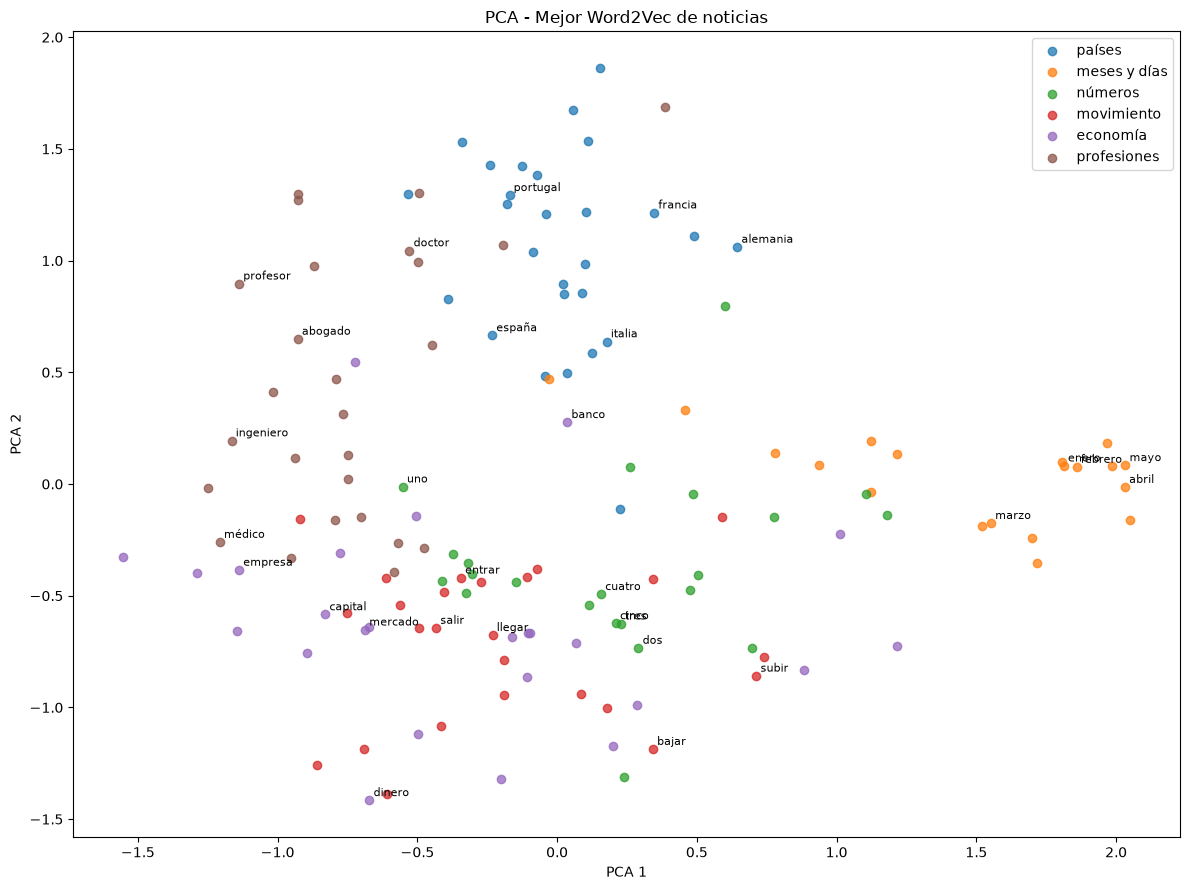

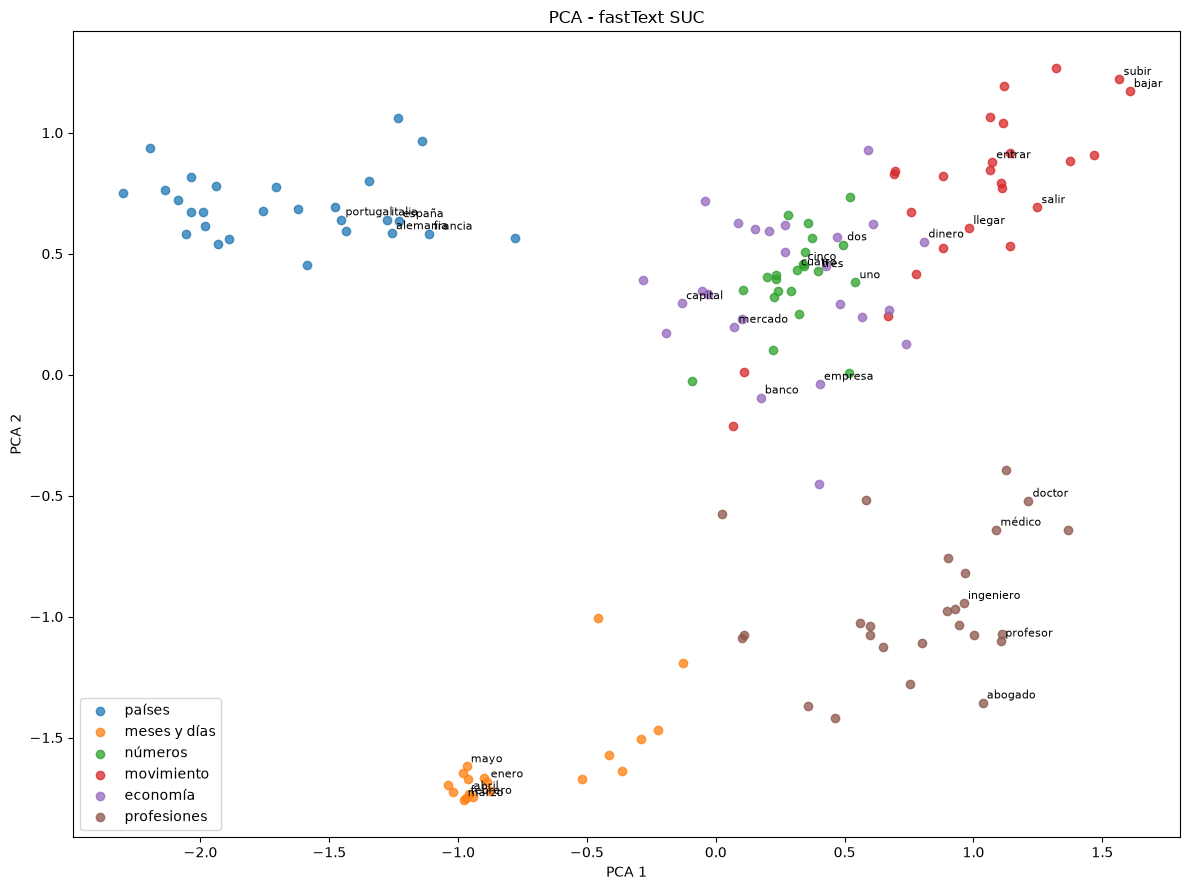

In [107]:
def graficar_pca(X, titulo):
    coordenadas = PCA(n_components=2, random_state=42).fit_transform(X)
    plt.figure(figsize=(12, 9))
    for grupo in grupos:
        idx = [i for i, g in enumerate(etiquetas_grupo) if g == grupo]
        plt.scatter(coordenadas[idx, 0], coordenadas[idx, 1], label=grupo, alpha=0.75)
        for i in idx[:5]:
            plt.annotate(palabras_vis[i], (coordenadas[i,0], coordenadas[i,1]), fontsize=8, xytext=(3,3), textcoords='offset points')
    plt.title(titulo)
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.legend()
    plt.tight_layout()
    plt.show()

graficar_pca(X_w2v, 'PCA - Mejor Word2Vec de noticias')
graficar_pca(X_suc, 'PCA - fastText SUC')


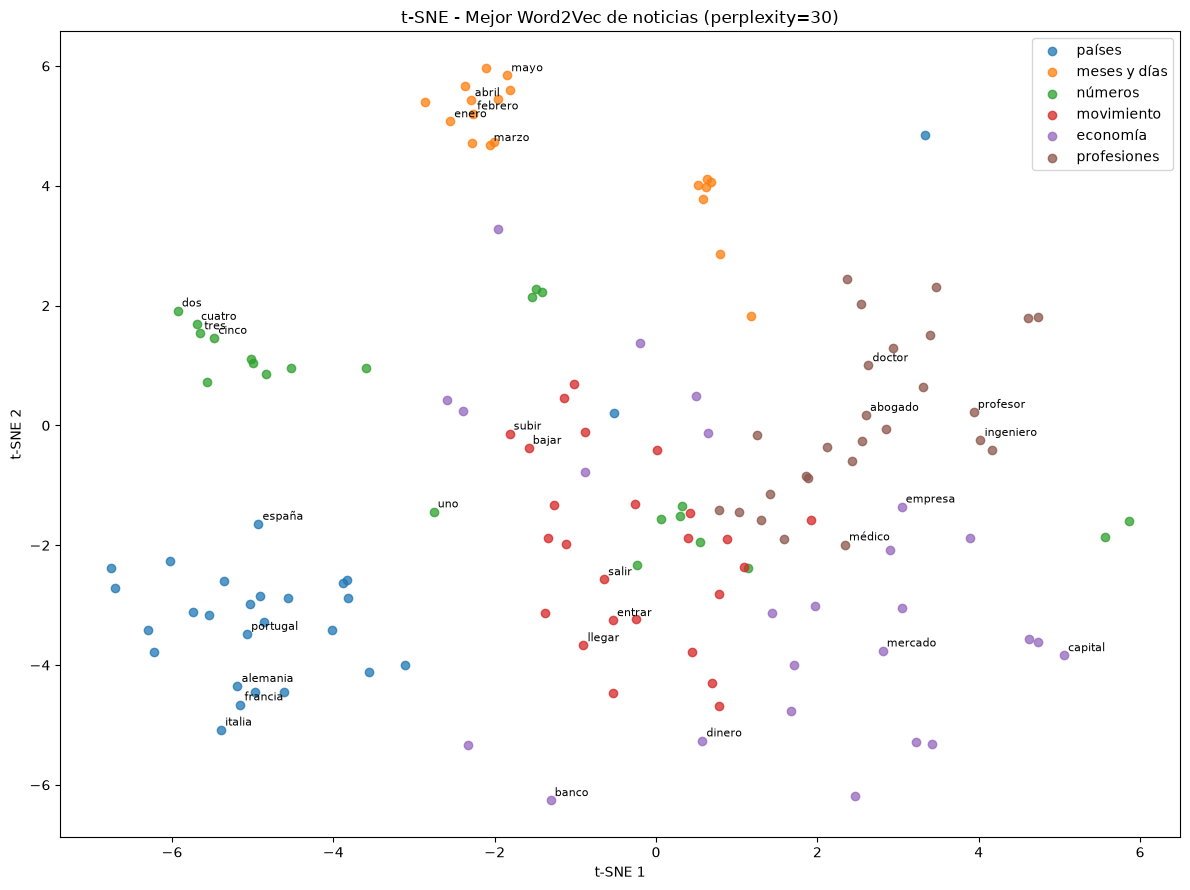

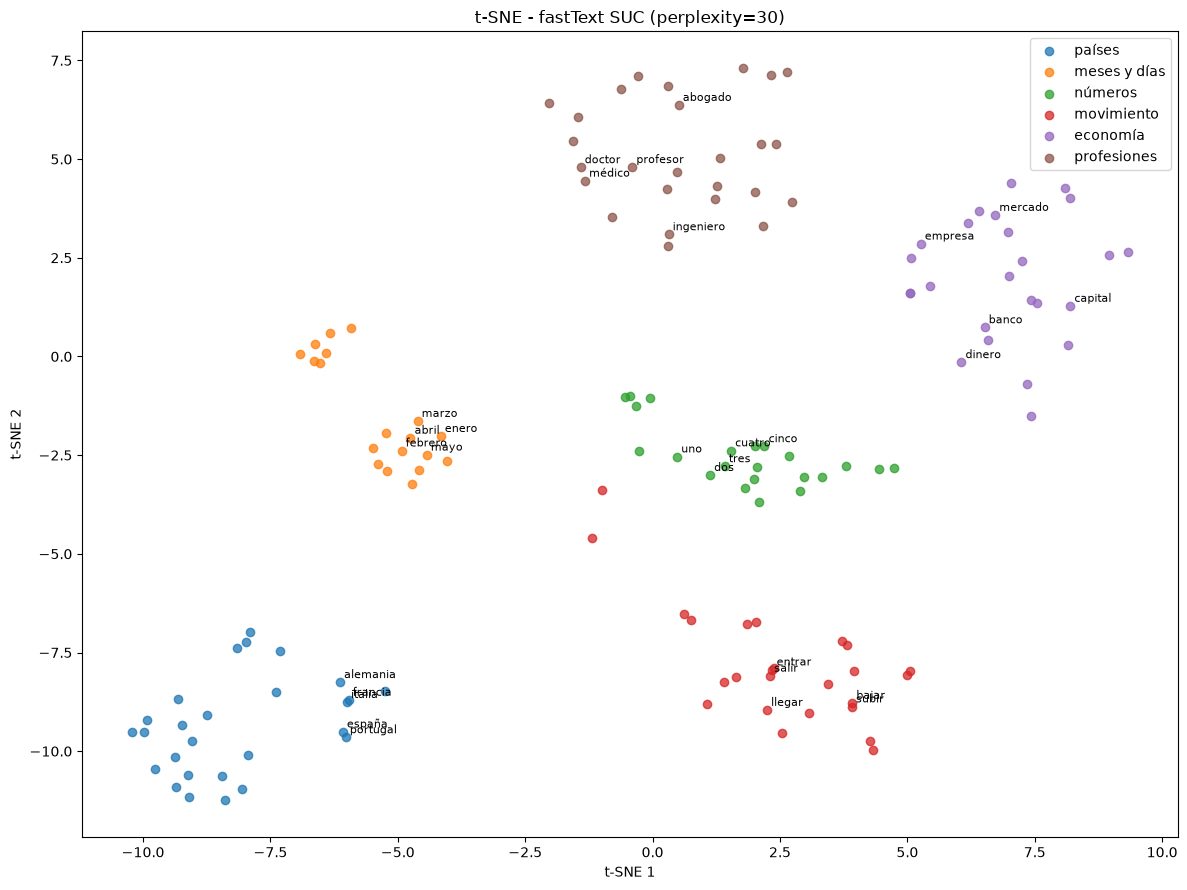

In [108]:
def graficar_tsne(X, titulo):
    n = len(X)
    perplexity = min(30, max(5, (n - 1) // 3))
    coordenadas = TSNE(
        n_components=2,
        random_state=42,
        perplexity=perplexity,
        init='pca',
        learning_rate='auto'
    ).fit_transform(X)

    plt.figure(figsize=(12, 9))
    for grupo in grupos:
        idx = [i for i, g in enumerate(etiquetas_grupo) if g == grupo]
        plt.scatter(coordenadas[idx, 0], coordenadas[idx, 1], label=grupo, alpha=0.75)
        for i in idx[:5]:
            plt.annotate(palabras_vis[i], (coordenadas[i,0], coordenadas[i,1]), fontsize=8, xytext=(3,3), textcoords='offset points')
    plt.title(f'{titulo} (perplexity={perplexity})')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.legend()
    plt.tight_layout()
    plt.show()

graficar_tsne(X_w2v, 't-SNE - Mejor Word2Vec de noticias')
graficar_tsne(X_suc, 't-SNE - fastText SUC')


**¿Se forman los grupos esperados? ¿En qué modelo se separan mejor?**

Sí, en general se forman, pero se ven mucho mejor en fastText SUC. En SUC, sobre todo en t-SNE, los seis grupos (países, meses y días, números, economía, profesiones y verbos de movimiento) forman regiones distintas; en PCA se separan menos y, por ejemplo, profesiones, números y movimiento se solapan. En el Word2Vec de noticias los grupos se distinguen peor y hay más palabras mezcladas entre grupos. Esto es esperable porque el modelo de noticias se entrenó con unos 637 mil tokens y SUC con miles de millones de palabras.

**Compare PCA y t-SNE: ¿por qué en t-SNE se puede confiar en los grupos pero no en la distancia entre grupos?**

PCA es una proyección lineal que conserva las direcciones de mayor varianza, así que las distancias se deforman poco, pero con solo dos componentes muchos grupos se solapan. t-SNE, en cambio, intenta que las palabras que son vecinas en el espacio original sigan siendo vecinas en 2D, y por eso separa mejor los grupos. Para lograrlo sacrifica las distancias grandes: la separación entre grupos, el tamaño de cada grupo y su posición dependen de la perplexity y de la semilla. Por eso se puede confiar en que las palabras de un mismo grupo son cercanas, pero no en qué tan lejos o cerca quedan unos grupos de otros.